# 10 · Robustness (Fig. 8)
Every ward diagnostic repeated in five populations: all sources, springs only (ponds excluded),
perennial sources only, perennial springs only, and sources inside the official polygon of their
recorded palika. The nulls are regrown on each population's own source graph. Running this notebook
reproduces `rb_sensitivity_subsets.csv`, `rb_null_distributions.csv`, the validation-distance tables
and the seismic adjustment (about ten minutes).

In [1]:
import logging, os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", stream=sys.stdout, force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

M = ROOT / "results/metrics"
F = ROOT / "results/figures"

def table(name, **kw):
    return pd.read_csv(M / name, **kw).round(4)

def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.robustness import run as run_robustness
run_robustness()

2026-11-10 16:05:44,642 [INFO] R3 validation distances


2026-11-10 16:05:45,151 [INFO] 
                       design  buffer_m  n_splits  mean_n_train  median_distance_m  p05_distance_m  share_test_within_500m  share_test_within_1km
0  leave-one-municipality-out     500.0        21      3786.714           2912.448         786.444                   0.000                  0.104
1            spatial block CV       0.0        25      3413.400           1898.874         356.874                   0.098                  0.253
2            spatial block CV     500.0        25      3315.760           2185.063         653.369                   0.000                  0.176
3            spatial block CV    1000.0        25      3120.440           2657.569        1169.419                   0.000                  0.000
4            spatial block CV    2000.0        25      2686.400           3697.258        2175.372                   0.000                  0.000


2026-11-10 16:05:45,152 [INFO] R4 earthquake adjustment


2026-11-10 16:06:51,898 [INFO] 
           variable  share_of_variance_within_wards  within_ward_sd  total_sd
0          pga_main                           0.110           1.707     5.138
1         pga_may12                           0.112           1.446     4.314
2  aftershocks_20km                           0.072           1.261     4.712
                                                                 model              term  coef_per_sd  ci_low  ci_high  ci_excludes_zero
0                                                seismic + environment          pga_main       -0.229  -0.704    0.071             False
1                                                seismic + environment         pga_may12        0.688   0.244    1.033              True
2                                                seismic + environment  aftershocks_20km       -0.243  -0.595    0.039             False
3                           seismic + environment + ward fixed effects          pga_main       -0.439  -1.04

2026-11-10 16:06:51,899 [INFO] R1/R2 null regions and sensitivity subsets


2026-11-10 16:06:54,173 [INFO] all sources: done


2026-11-10 16:06:55,714 [INFO] springs only (ponds excluded): done


2026-11-10 16:06:57,211 [INFO] perennial only (seasonal excluded): done


2026-11-10 16:06:58,618 [INFO] perennial springs only: done


2026-11-10 16:07:00,163 [INFO] located in recorded palika: done


2026-11-10 16:07:00,171 [INFO] 
                                                        0                              1                                   2                       3                           4
subset                                        all sources  springs only (ponds excluded)  perennial only (seasonal excluded)  perennial springs only  located in recorded palika
n                                                    5689                           5168                                4759                    4477                        5306
n_dried                                              1521                           1264                                 934                     835                        1422
drying_rate                                         0.267                          0.245                               0.196                   0.187                       0.268
ward_icc                                            0.132                          

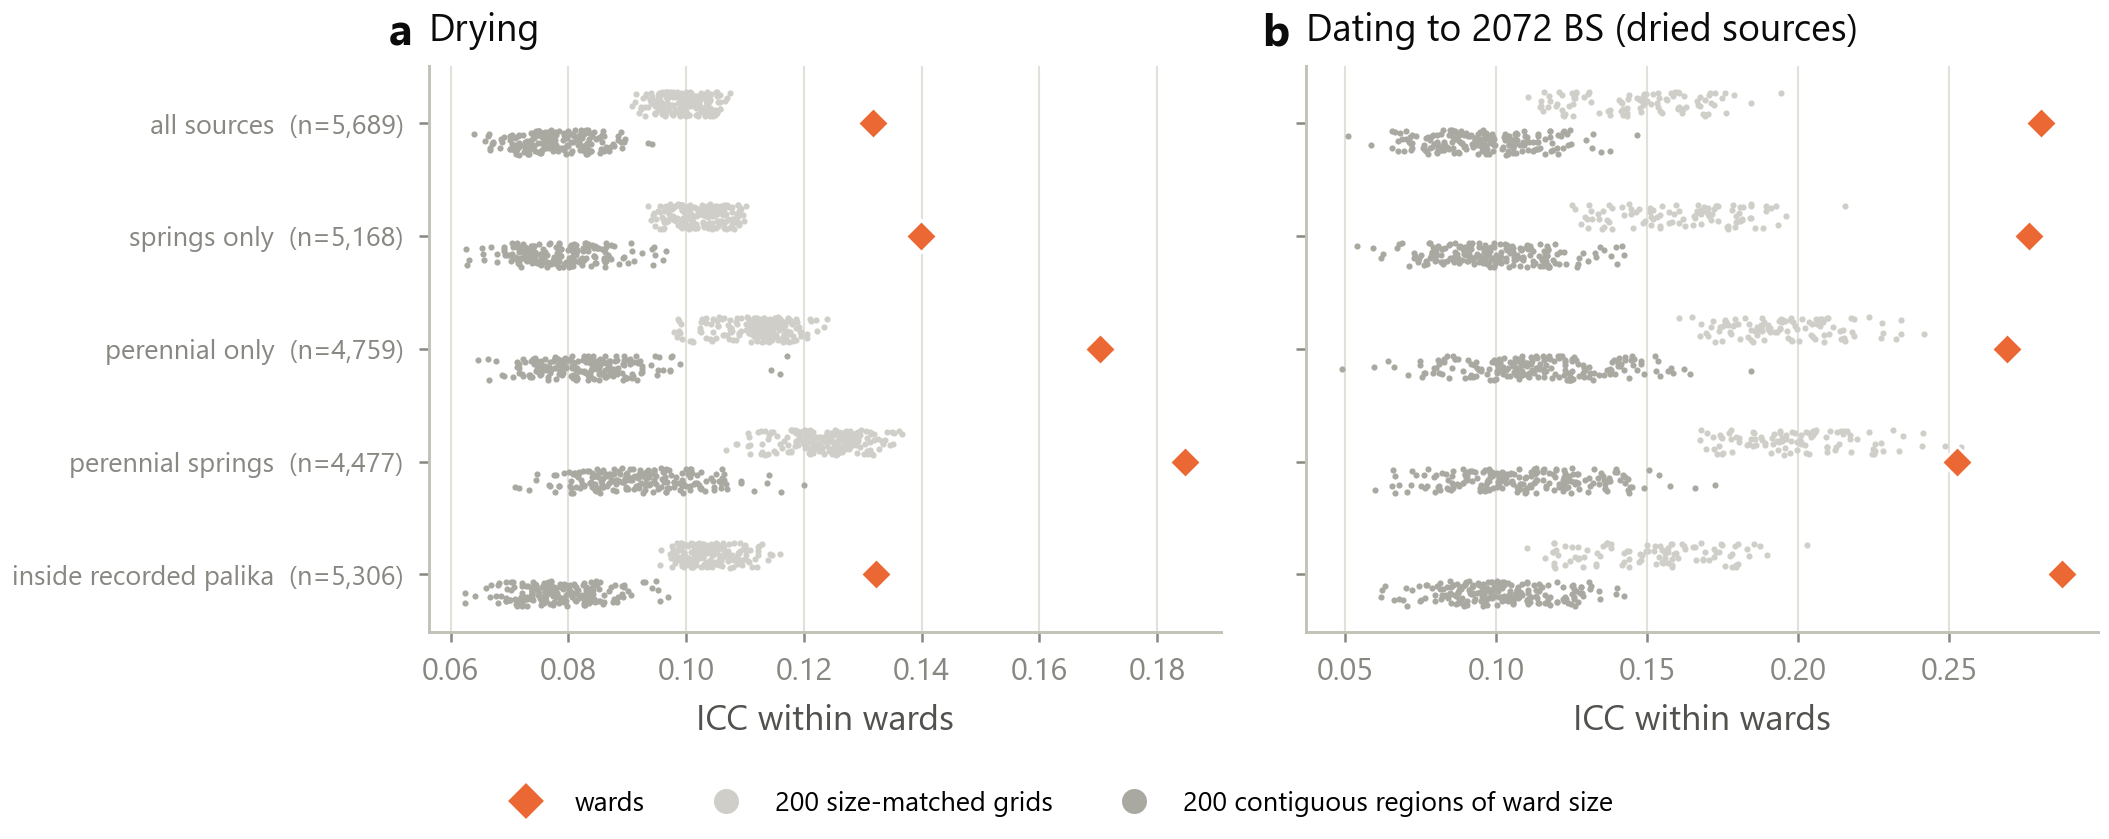

In [3]:
fig("fig8_robustness.png")

In [4]:
table("rb_sensitivity_subsets.csv").set_index("subset").T

subset,all sources,springs only (ponds excluded),perennial only (seasonal excluded),perennial springs only,located in recorded palika
n,5689.0000,5168.0000,4759.0000,4477.0000,5306.0000
n_dried,1521.0000,1264.0000,934.0000,835.0000,1422.0000
drying_rate,0.2674,0.2446,0.1963,0.1865,0.2680
ward_icc,0.1318,0.1399,0.1704,0.1847,0.1322
ward_grid_q025,0.0923,0.0949,0.0990,0.1107,0.0976
ward_grid_q975,0.1057,0.1091,0.1211,0.1346,0.1123
ward_p_grid,0.0050,0.0050,0.0050,0.0050,0.0050
ward_region_q025,0.0667,0.0656,0.0691,0.0766,0.0668
ward_region_q975,0.0889,0.0942,0.0973,0.1094,0.0929
ward_p_region,0.0050,0.0050,0.0050,0.0050,0.0050


## Explore: a small fresh set of contiguous placebo partitions (no cache)

In [5]:
from src.dataset import load_master, coords_to_metric
from src.catchment_analysis import icc1
from src.regions import sample_partitions

df = load_master()
coords = coords_to_metric(df.latitude.to_numpy(), df.longitude.to_numpy())
ward = (df.municipality.astype(str) + "_" + df.ward.astype(str)).to_numpy()
y = df.target_dried.to_numpy().astype(float)
parts = sample_partitions(coords, ward, 50, seed=1, cache=False)
null = np.array([icc1(y, p) for p in parts])
print(f"ward ICC {icc1(y, ward):.3f}; 50 contiguous placebo partitions: "
      f"{np.quantile(null, .025):.3f}-{np.quantile(null, .975):.3f} (max {null.max():.3f})")

ward ICC 0.132; 50 contiguous placebo partitions: 0.067-0.085 (max 0.085)
